PatchTST and Chronos

Data Efficiency Comparision:

PatchTST  — full training data  vs.  10% training data

Chronos   — full-context zero-shot  vs.  short-context zero-shot

1. Install dependencies

In [1]:
!pip install -q neuralforecast chronos-forecasting pandas numpy torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.0/302.0 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.6/80.6 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.6/348.6 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 831.6/831.6 kB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.2/74.2 MB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 31.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 64.5 MB/s eta 0:00:00


In [2]:
import glob
import os
import time
import numpy as np
import pandas as pd
import torch
from neuralforecast import NeuralForecast
from neuralforecast.models import PatchTST
from neuralforecast.losses.pytorch import MSE
from chronos import ChronosPipeline

2. Configuration

In [3]:
DATA_DIR = "/content/Dataset"
HORIZONS = [24, 48, 96, 192, 336]
TEST_FRAC = 0.20                          # last 20% of each series held out as test (shared by both models)
EVAL_MAX_WINDOWS_PER_SERIES = 20          # cap rolling-eval windows per file, sampled evenly across test period
RANDOM_SEED = 42
RESULTS_CSV = "results_data_efficiency_comparison.csv"

In [4]:
# --- PatchTST settings ---
PATCHTST_INPUT_LEN = 512
PATCHTST_MAX_STEPS = 200
PATCHTST_TRAIN_FRACS = [1.0, 0.10]        # full data vs 10% low-data

# --- Chronos settings ---
CHRONOS_MODEL_NAME = "amazon/chronos-t5-small"
CHRONOS_FULL_CONTEXT = 512                # matches PatchTST's input length, for fair comparison
CHRONOS_SHORT_CONTEXT = 51                # ~10% of full context — the "low-data" analog for a zero-shot model
CHRONOS_NUM_SAMPLES = 20                  # Chronos forecasts probabilistically; we take the median as point forecast


DATETIME_HINTS = ["date/time", "date_time", "datetime", "timestamp", "date", "time"]
TARGET_HINTS = [
    "lv activepower", "active power", "activepower", "power (kw)", "power(kw)",
    "power output", "generated power", "wind power", "power",
]
TARGET_EXCLUDE_HINTS = ["theoretical", "curve"]
MANUAL_OVERRIDES = {}   # e.g. {"turbine_3.csv": {"datetime": "Date/Time", "target": "LV ActivePower (kW)"}}

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")      # full data vs 10% low-data

import logging as _logging
for _name in ("pytorch_lightning", "lightning", "lightning.pytorch"):
    _logging.getLogger(_name).setLevel(_logging.ERROR)
os.environ["TQDM_DISABLE"] = "1"

FAST_MODE = False
if FAST_MODE:
    HORIZONS = [24, 96]
    PATCHTST_MAX_STEPS = 50
    CHRONOS_NUM_SAMPLES = 5
    EVAL_MAX_WINDOWS_PER_SERIES = 5
    print("*** FAST_MODE is ON — results are for pipeline sanity-checking only, "
          "not for your final table. Set FAST_MODE=False for real results. ***")


Using device: cuda


3. Load + auto-detect columns, combine all CSVs

In [5]:
def find_column(columns, hints, exclude_hints=None):
    cols_lower = {c: c.lower() for c in columns}
    exclude_hints = exclude_hints or []
    for hint in hints:
        for c, cl in cols_lower.items():
            if hint in cl and not any(ex in cl for ex in exclude_hints):
                return c
    return None


def load_one_csv(path):
    fname = os.path.basename(path)
    df = pd.read_csv(path)
    override = MANUAL_OVERRIDES.get(fname, {})
    dt_col = override.get("datetime") or find_column(df.columns, DATETIME_HINTS)
    target_col = override.get("target") or find_column(
        df.columns, TARGET_HINTS, exclude_hints=TARGET_EXCLUDE_HINTS
    )
    if dt_col is None or target_col is None:
        print(f"  [SKIP] {fname}: could not auto-detect columns "
              f"(datetime={dt_col}, target={target_col}). Add to MANUAL_OVERRIDES.")
        return None
    print(f"  [OK]   {fname}: datetime_col='{dt_col}', target_col='{target_col}'")
    out = pd.DataFrame()
    out["ds"] = pd.to_datetime(df[dt_col], errors="coerce", dayfirst=True)
    out["y"] = pd.to_numeric(df[target_col], errors="coerce")
    out["unique_id"] = os.path.splitext(fname)[0]
    out = out.dropna(subset=["ds", "y"]).sort_values("ds")
    out = out.drop_duplicates(subset=["ds"])
    return out.reset_index(drop=True)


csv_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
if not csv_paths:
    raise FileNotFoundError(f"No .csv files found in {DATA_DIR}.")

print(f"Found {len(csv_paths)} CSV file(s) in {DATA_DIR}:")
frames = [load_one_csv(p) for p in csv_paths]
min_len_needed = PATCHTST_INPUT_LEN + max(HORIZONS) + 10
frames = [f for f in frames if f is not None and len(f) > min_len_needed]
if not frames:
    raise ValueError("No usable series after loading — check MANUAL_OVERRIDES or series length.")

df = pd.concat(frames, ignore_index=True)
print(f"\nLoaded {df.unique_id.nunique()} series, {len(df)} total rows.")


def infer_freq(df):
    one_series = df[df.unique_id == df.unique_id.iloc[0]].sort_values("ds")
    diffs = one_series["ds"].diff().dropna()
    if diffs.empty:
        return "H"
    try:
        return pd.tseries.frequencies.to_offset(diffs.mode().iloc[0]).freqstr
    except Exception:
        return "H"


FREQ = infer_freq(df)
print(f"Inferred sampling frequency: {FREQ}")

Found 4 CSV file(s) in /content/Dataset:
  [OK]   Location1.csv: datetime_col='Time', target_col='Power'
  [OK]   Location2.csv: datetime_col='Time', target_col='Power'
  [OK]   Location3.csv: datetime_col='Time', target_col='Power'
  [OK]   Location4.csv: datetime_col='Time', target_col='Power'

Loaded 4 series, 69024 total rows.
Inferred sampling frequency: h


4. Shared test-window builder — SAME forecast origins used by both models

In [6]:
def build_test_contexts(df, horizon, lookback):
    """
    For each series, holds out the last TEST_FRAC as test and returns a dict
    {unique_id: context_df} where context_df = lookback window + held-out
    test region, for rolling-window evaluation. Using the same TEST_FRAC and
    horizon across models keeps forecast origins aligned.
    """
    contexts = {}
    for uid, g in df.groupby("unique_id"):
        g = g.sort_values("ds").reset_index(drop=True)
        n = len(g)
        n_test = max(int(n * TEST_FRAC), horizon + 10)
        n_train_full = n - n_test
        if n_train_full < lookback:
            continue
        contexts[uid] = g.iloc[max(n_train_full - lookback, 0):].reset_index(drop=True)
    return contexts


def make_windows(contexts, horizon, lookback):
    """Yields (synthetic_uid, context_slice_df, true_future_values) for each
    evaluation window, capped/sampled per EVAL_MAX_WINDOWS_PER_SERIES."""
    step = horizon
    windows = []
    for uid, ctx_full in contexts.items():
        n_windows = max((len(ctx_full) - lookback - horizon) // step + 1, 0)
        if n_windows > EVAL_MAX_WINDOWS_PER_SERIES:
            chosen = sorted(set(np.linspace(0, n_windows - 1, EVAL_MAX_WINDOWS_PER_SERIES).astype(int).tolist()))
        else:
            chosen = list(range(n_windows))
        for w in chosen:
            start = lookback + w * step
            ctx = ctx_full.iloc[start - lookback:start]
            true_future = ctx_full.iloc[start:start + horizon]
            if len(true_future) < horizon or len(ctx) < lookback:
                continue
            windows.append((f"{uid}__w{w}", ctx, true_future["y"].values))
    return windows

5. PatchTST: train on train_frac, evaluate on shared windows (batched)

In [7]:
def run_patchtst(df, horizon, train_frac):
    # Build training data sized by train_frac (most recent slice of the pre-test region)
    train_parts = []
    for uid, g in df.groupby("unique_id"):
        g = g.sort_values("ds").reset_index(drop=True)
        n = len(g)
        n_test = max(int(n * TEST_FRAC), horizon + 10)
        n_train_full = n - n_test
        if n_train_full < PATCHTST_INPUT_LEN + horizon + 10:
            continue
        n_train = max(int(n_train_full * train_frac), PATCHTST_INPUT_LEN + horizon + 10)
        n_train = min(n_train, n_train_full)
        train_parts.append(g.iloc[n_train_full - n_train:n_train_full])
    if not train_parts:
        print(f"  [SKIP] PatchTST horizon={horizon}, train_frac={train_frac}: no series long enough.")
        return None
    train_df = pd.concat(train_parts, ignore_index=True)

    model = PatchTST(
        h=horizon, input_size=PATCHTST_INPUT_LEN, patch_len=16, stride=8,
        max_steps=PATCHTST_MAX_STEPS, loss=MSE(), scaler_type="standard",
        random_seed=RANDOM_SEED,
        enable_progress_bar=False,   # progress-bar printing is a real Colab slowdown, not just cosmetic
    )
    nf = NeuralForecast(models=[model], freq=FREQ)

    t0 = time.time()
    # val_size=0: skip NeuralForecast's internal validation split.
    nf.fit(df=train_df, val_size=0)
    train_time_sec = time.time() - t0

    contexts = build_test_contexts(df, horizon, PATCHTST_INPUT_LEN)
    windows = make_windows(contexts, horizon, PATCHTST_INPUT_LEN)
    if not windows:
        print(f"  [SKIP] PatchTST horizon={horizon}, train_frac={train_frac}: no evaluable windows.")
        return None

    batch_parts = []
    for synth_uid, ctx, _ in windows:
        ctx = ctx.copy()
        ctx["unique_id"] = synth_uid
        batch_parts.append(ctx)
    batch_df = pd.concat(batch_parts, ignore_index=True)

    t1 = time.time()
    fcst = nf.predict(df=batch_df)
    total_predict_sec = time.time() - t1
    avg_latency_ms = (total_predict_sec / len(windows)) * 1000

    fcst_by_uid = fcst.set_index("unique_id")["PatchTST"]
    preds = np.concatenate([fcst_by_uid.loc[uid].values[:horizon] for uid, _, _ in windows])
    actuals = np.concatenate([fut for _, _, fut in windows])

    n_params = sum(p.numel() for p in model.state_dict().values())
    return {
        "model": "PatchTST",
        "data_setting": "full_data" if train_frac == 1.0 else f"{int(train_frac*100)}pct_data",
        "horizon": horizon,
        "mse": float(np.mean((preds - actuals) ** 2)),
        "mae": float(np.mean(np.abs(preds - actuals))),
        "train_time_sec": round(train_time_sec, 2),
        "inference_latency_ms": round(avg_latency_ms, 2),
        "n_params": n_params,
    }

6. Chronos: zero-shot at full context vs. short context (batched)

In [8]:
print(f"\nLoading {CHRONOS_MODEL_NAME}...")
chronos_pipeline = ChronosPipeline.from_pretrained(
    CHRONOS_MODEL_NAME, device_map=DEVICE,
    torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
)
chronos_n_params = sum(p.numel() for p in chronos_pipeline.model.parameters())
print(f"Chronos loaded: {chronos_n_params:,} parameters.")


def run_chronos(df, horizon, context_len, setting_label):

    contexts = build_test_contexts(df, horizon, CHRONOS_FULL_CONTEXT)
    windows = make_windows(contexts, horizon, CHRONOS_FULL_CONTEXT)
    if not windows:
        print(f"  [SKIP] Chronos horizon={horizon}, {setting_label}: no evaluable windows.")
        return None

    context_tensors = [
        torch.tensor(ctx["y"].values[-context_len:], dtype=torch.float32)
        for _, ctx, _ in windows
    ]

    t0 = time.time()
    forecasts = chronos_pipeline.predict(
        context_tensors, prediction_length=horizon, num_samples=CHRONOS_NUM_SAMPLES,
    )
    total_predict_sec = time.time() - t0
    avg_latency_ms = (total_predict_sec / len(windows)) * 1000

    preds, actuals = [], []
    for i, (_, _, true_future) in enumerate(windows):
        sample_arr = forecasts[i].numpy() if hasattr(forecasts[i], "numpy") else np.asarray(forecasts[i])
        preds.append(np.median(sample_arr, axis=0))
        actuals.append(true_future)
    preds = np.concatenate(preds)
    actuals = np.concatenate(actuals)

    return {
        "model": "Chronos",
        "data_setting": setting_label,
        "horizon": horizon,
        "mse": float(np.mean((preds - actuals) ** 2)),
        "mae": float(np.mean(np.abs(preds - actuals))),
        "train_time_sec": 0.0,  # no training pipeline — zero-shot
        "inference_latency_ms": round(avg_latency_ms, 2),
        "n_params": chronos_n_params,
    }


Loading amazon/chronos-t5-small...


config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  185MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

Chronos loaded: 46,154,240 parameters.


Output: results_data_efficiency_comparison.csv

7. Run the full sweep: 4 settings x all horizons

In [9]:
results = []
for h in HORIZONS:
    print(f"\n=== Horizon={h} ===")
    for frac in PATCHTST_TRAIN_FRACS:
        print(f"  PatchTST, train_frac={frac}...")
        res = run_patchtst(df, h, frac)
        if res:
            results.append(res)
            print(f"    -> MSE={res['mse']:.4f}, MAE={res['mae']:.4f}")

    print(f"  Chronos, full_context ({CHRONOS_FULL_CONTEXT} pts)...")
    res = run_chronos(df, h, CHRONOS_FULL_CONTEXT, "zero_shot_full_context")
    if res:
        results.append(res)
        print(f"    -> MSE={res['mse']:.4f}, MAE={res['mae']:.4f}")

    print(f"  Chronos, short_context ({CHRONOS_SHORT_CONTEXT} pts, ~10% of full)...")
    res = run_chronos(df, h, CHRONOS_SHORT_CONTEXT, "zero_shot_short_context_10pct")
    if res:
        results.append(res)
        print(f"    -> MSE={res['mse']:.4f}, MAE={res['mae']:.4f}")

results_df = pd.DataFrame(results)
results_df = results_df[["model", "data_setting", "horizon", "mse", "mae",
                          "train_time_sec", "inference_latency_ms", "n_params"]]
results_df = results_df.sort_values(["horizon", "model", "data_setting"]).reset_index(drop=True)
results_df.to_csv(RESULTS_CSV, index=False)
print(f"\nSaved results to {RESULTS_CSV}\n")
print(results_df.to_string(index=False))
print("\n--- Markdown table for write-up ---\n")
print(results_df.to_markdown(index=False))

INFO:lightning_fabric.utilities.seed:Seed set to 42



=== Horizon=24 ===
  PatchTST, train_frac=1.0...


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO:lightning_fabric.utilities.seed:Seed set to 42


    -> MSE=0.0437, MAE=0.1574
  PatchTST, train_frac=0.1...


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


    -> MSE=0.0486, MAE=0.1644
  Chronos, full_context (512 pts)...
    -> MSE=0.0522, MAE=0.1500
  Chronos, short_context (51 pts, ~10% of full)...


... (23 outputs left out)

    -> MSE=0.0521, MAE=0.1798
  PatchTST, train_frac=0.1...


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


    -> MSE=0.0687, MAE=0.2039
  Chronos, full_context (512 pts)...


    -> MSE=0.0800, MAE=0.1946
  Chronos, short_context (51 pts, ~10% of full)...
    -> MSE=0.0958, MAE=0.2203

Saved results to results_data_efficiency_comparison.csv

   model                  data_setting  horizon      mse      mae  train_time_sec  inference_latency_ms  n_params
 Chronos        zero_shot_full_context       24 0.052236 0.149990            0.00                 77.26  46154240
 Chronos zero_shot_short_context_10pct       24 0.057925 0.155958            0.00                 18.68  46154240
PatchTST                    10pct_data       24 0.048633 0.164398           39.78                  2.37    605985
PatchTST                     full_data       24 0.043725 0.157352           48.47                  2.27    605985
 Chronos        zero_shot_full_context       48 0.059515 0.170113            0.00                110.57  46154240
 Chronos zero_shot_short_context_10pct       48 0.088392 0.211137            0.00                 36.38  46154240
PatchTST                    10pct

8. Plot: MSE vs horizon, all four settings

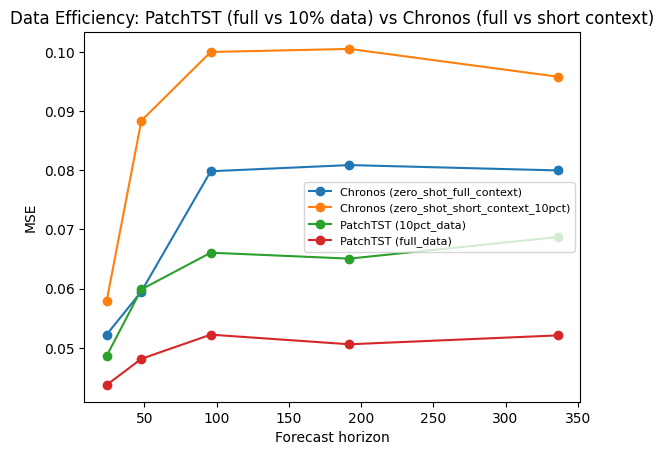

In [ ]:
import matplotlib.pyplot as plt

for (model, setting), sub in results_df.groupby(["model", "data_setting"]):
    sub = sub.sort_values("horizon")
    plt.plot(sub.horizon, sub.mse, marker="o", label=f"{model} ({setting})")
plt.xlabel("Forecast horizon")
plt.ylabel("MSE")
plt.title("Data Efficiency: PatchTST (full vs 10% data) vs Chronos (full vs short context)")
plt.legend(fontsize=8)
plt.show()